# Devoir 5 - Solaire et applications
### Ève Castonguay & Tristan Tessier 

## **Question 1 - Étude paramétrique**

In [1]:
# Imports
using Pkg
Pkg.activate(".")
Pkg.add("LaTeXStrings")   
Pkg.instantiate()
using DataFrames  
using Dates  
using CSV  
using Statistics  
using PlotlyJS 
using Unitful
using Printf
using LaTeXStrings 
using Glob # * dans les str

  Activating project at `~/Desktop/Solaire/D5`
     Project No packages added to or removed from `~/Desktop/Solaire/D5/Project.toml`
    Manifest No packages added to or removed from `~/Desktop/Solaire/D5/Manifest.toml`


In [2]:
# Folder names
depart_flder = "/Users/evecastonguay/Library/CloudStorage/OneDrive-polymtl/Aut. 2026 - Polytechnique/Solaire/D5/"

# File names
thermal = "*-Thermal.csv"
pv = "*-PvDetails.csv"
building = "*-Building.csv"
checks = "*-Checks.csv"
integrals = "Integrals copie.csv"

file_list = [thermal,pv,building,checks,integrals]

5-element Vector{String}:
 "*-Thermal.csv"
 "*-PvDetails.csv"
 "*-Building.csv"
 "*-Checks.csv"
 "Integrals copie.csv"

In [3]:
# Remove first December month
function remove_december(df)
    start_hour = 8760
    end_hour = 17520
    df_year = df[start_hour .<= df[:, 1] .<= end_hour, :]
    return df_year
end

remove_december (generic function with 1 method)

## Rendement capteurs thermiques

In [11]:
df = CSV.read(glob(file_list[5],depart_flder)[1], DataFrame) # glob(pattern,dossier) returns array

Row,TIME,slope,Ag,Vs,PPeakPv,CBat,QHeatLoad,QDhwLoad,QCoolLoad,PLightAppl,PCool,PAuxHeat,PAuxDhw,PPump,PTot,EincCol,QuCol,QSolTank,QTankHeat,QTankDhw,QTankEnv,dETank,etaCol,fSolThermal,EincPv,PPv,PLoad,PDumped,PGrid,dEBat,etaPv,fSolElectrical,Column33
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Missing
1,17520.0,45.0,10.0,5.0,5.0,10.0,2.76318e7,1.07063e7,1.36555e6,1.49595e7,5.46221e5,2.45678e7,5.01377e6,1.10506e6,4.61923e7,6.32222e7,2.04853e7,8.63805e6,2.12504e6,5.69248e6,819718.0,-7.0622e-10,0.32402,0.228404,2.03388e8,3.0972e7,4.61943e7,9.52119e6,2.81948e7,5243.26,0.15228,0.389621,missing
2,17520.0,45.0,10.0,20.0,5.0,10.0,2.76318e7,1.06599e7,1.36555e6,1.49595e7,5.46221e5,2.16159e7,2.56148e6,1.00238e6,4.06855e7,6.32222e7,2.23209e7,1.59794e7,6.0108e6,8.09846e6,1.87009e6,5.33984e-10,0.353055,0.368601,2.03388e8,3.0972e7,4.06862e7,1.05166e7,2.35568e7,-4.01219,0.15228,0.421002,missing
3,17520.0,45.0,10.0,100.0,5.0,10.0,2.76318e7,1.06584e7,1.36555e6,1.49595e7,5.46221e5,1.85802e7,1.87979e6,1.09901e6,3.70647e7,6.32222e7,2.47382e7,2.15284e7,9.06832e6,8.77861e6,3.68149e6,-5.81571e-8,0.391289,0.465661,2.03388e8,3.0972e7,3.70648e7,1.06181e7,1.99432e7,-172.671,0.15228,0.461934,missing
4,17520.0,45.0,10.0,500.0,5.0,10.0,2.76318e7,1.06575e7,1.36555e6,1.49595e7,5.46221e5,1.79922e7,1.91374e6,1.21637e6,3.6628e7,6.32222e7,2.78234e7,2.46846e7,9.64133e6,8.74379e6,6.29949e6,-9.13566e-5,0.440089,0.48012,2.03388e8,3.0972e7,3.66281e7,1.04286e7,1.93151e7,1.36105,0.15228,0.472668,missing
5,17520.0,45.0,20.0,5.0,5.0,10.0,2.76318e7,1.0701e7,1.36555e6,1.49595e7,5.46221e5,2.17173e7,3.12951e6,1.42704e6,4.17796e7,1.26444e8,2.55239e7,1.48017e7,5.64567e6,7.5715e6,1.58515e6,2.89099e-10,0.201859,0.351814,2.03388e8,3.0972e7,4.17813e7,1.04207e7,2.46264e7,-209.17,0.15228,0.410564,missing
6,17520.0,45.0,20.0,20.0,5.0,10.0,2.76318e7,1.06616e7,1.36555e6,1.49595e7,5.46221e5,1.64938e7,1.45293e6,1.52064e6,3.49731e7,1.26444e8,3.32118e7,2.34897e7,1.1145e7,9.2087e6,3.13581e6,-4.35458e-9,0.262659,0.531338,2.03388e8,3.0972e7,3.49736e7,1.09034e7,1.82037e7,11.189,0.15228,0.479495,missing
7,17520.0,45.0,20.0,100.0,5.0,10.0,2.76318e7,1.06598e7,1.36555e6,1.49595e7,5.46221e5,1.14128e7,1.07401e6,1.73203e6,2.97246e7,1.26444e8,3.77967e7,3.17496e7,1.62323e7,9.5858e6,5.93152e6,0.000919911,0.298919,0.673903,2.03388e8,3.0972e7,2.97247e7,1.11228e7,1.30905e7,133.75,0.15228,0.559608,missing
8,17520.0,45.0,20.0,500.0,5.0,10.0,2.76318e7,1.06589e7,1.36555e6,1.49595e7,5.46221e5,1.07293e7,1.08745e6,1.98086e6,2.93034e7,1.26444e8,4.34766e7,3.72307e7,1.69026e7,9.57141e6,1.07568e7,-5.87088,0.34384,0.691393,2.03388e8,3.0972e7,2.93035e7,1.07599e7,1.23315e7,-96.3696,0.15228,0.579178,missing
9,17520.0,45.0,50.0,5.0,5.0,10.0,2.76318e7,1.06796e7,1.36555e6,1.49595e7,5.46221e5,1.61935e7,1.39548e6,2.59416e6,3.56889e7,3.16111e8,4.63404e7,2.36453e7,1.13897e7,9.2841e6,2.97106e6,-2.08743e-10,0.146595,0.540895,2.03388e8,3.0972e7,3.56899e7,1.04117e7,1.84826e7,1.65513,0.15228,0.48212,missing


In [13]:
rename!(df, strip.(names(df))) # remove spaces after column names
## New dataframe : allows for selection of iseful vars only + adding units to these vars
stats = DataFrame(
    Ag = df.Ag .* u"m^2",
    Vs = df.Vs .* u"L/m^2",
    QHeatLoad = df.QHeatLoad .* u"kJ",
    QDhwLoad = df.QDhwLoad .* u"kJ",
    PAuxHeat = df.PAuxHeat .* u"kJ",
    PAuxDhw = df.PAuxDhw .* u"kJ",
    EincCol = df.EincCol .* u"kJ",
    QuCol = df.QuCol .* u"kJ"
)
# Rendement
η_col = stats.QuCol ./ stats.EincCol;
# Fraction solaire thermique
f_sol_thermal = 1 .- (stats.PAuxHeat .+ stats.PAuxDhw) ./ (stats.QHeatLoad .+ stats.QDhwLoad);

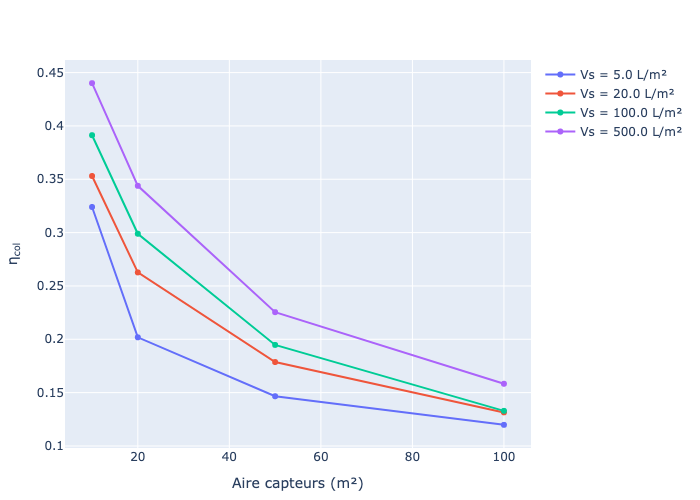

"eta-Ag.png"

In [ ]:
# Trace
traces = [scatter(x = ustrip.(stats.Ag[stats.Vs .== v]),
                  y = ustrip.(η_col[stats.Vs .== v]),
                  mode = "lines+markers",
                  name = "Vs = $(ustrip(v)) L/m²")
          for v in unique(stats.Vs)]

# Plot
fig = plot(traces, Layout(width = 800, height = 400,
                           xaxis_title = "Aire capteurs (m²)",
                           yaxis_title = "η<sub>col</sub>"))

# Save
display(fig)
savefig(fig, "eta-Ag.png", scale = 5)

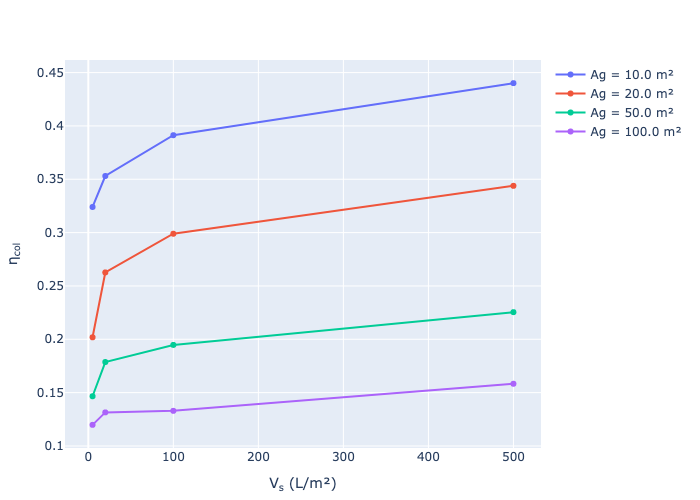

"eta-Vs.png"

In [30]:
# Trace
traces = [scatter(x = ustrip.(stats.Vs[stats.Ag .== a]),
                  y = ustrip.(η_col[stats.Ag .== a]),
                  mode = "lines+markers",
                  name = "Ag = $(ustrip(a)) m²")
          for a in unique(stats.Ag)]

# Plot
fig = plot(traces, Layout(width = 800, height = 400, 
                           xaxis_title = "V<sub>s</sub> (L/m²)",
                           yaxis_title = "η<sub>col</sub>"))

# Save
display(fig)
savefig(fig, "eta-Vs.png", scale = 5)

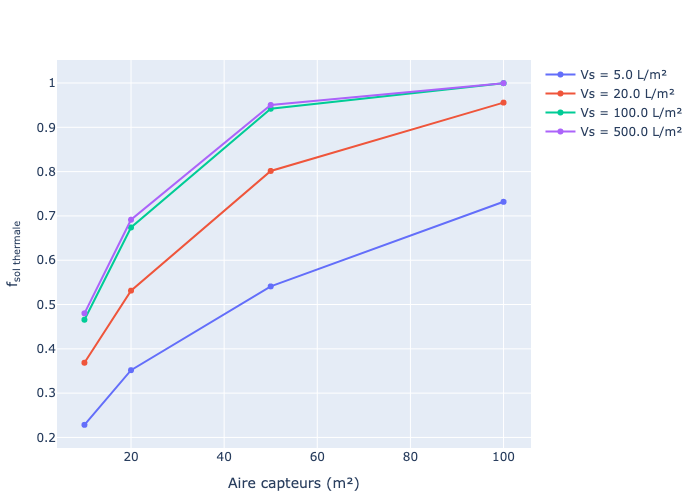

"f_sol_th-Ag.png"

In [ ]:
# Trace
traces = [scatter(x = ustrip.(stats.Ag[stats.Vs .== v]),
                  y = ustrip.(f_sol_thermal[stats.Vs .== v]),
                  mode = "lines+markers",
                  name = "Vs = $(ustrip(v)) L/m²")
          for v in unique(stats.Vs)]

# Plot
fig = plot(traces, Layout(width = 800, height = 400,
                           xaxis_title = "Aire capteurs (m²)",
                           yaxis_title = "f<sub>sol,thermale</sub>"))

# Save
display(fig)
savefig(fig, "f_sol_th-Ag.png", scale = 5)

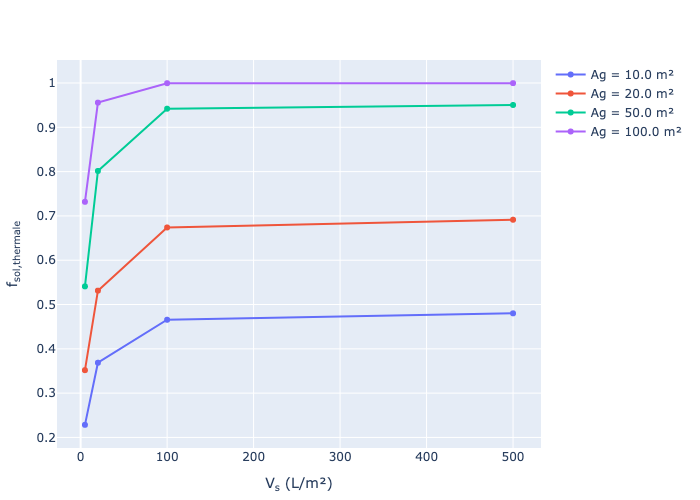

"f_sol_therm-Vs.png"

In [31]:
# Trace
traces = [scatter(x = ustrip.(stats.Vs[stats.Ag .== a]),
                  y = ustrip.(f_sol_thermal[stats.Ag .== a]),
                  mode = "lines+markers",
                  name = "Ag = $(ustrip(a)) m²")
          for a in unique(stats.Ag)]

# Plot
fig = plot(traces, Layout(width = 800, height = 400, 
                           xaxis_title = "V<sub>s</sub> (L/m²)",
                           yaxis_title = "f<sub>sol,thermale</sub>"))

# Save
display(fig)
savefig(fig, "f_sol_therm-Vs.png", scale = 5)